In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models  # add model to the list
from torchvision.utils import make_grid
import os


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

import warnings

warnings.filterwarnings("ignore")


from my_models import ConvolutionaNetwork_CATS_DOGS, AlexNetEdition

In [2]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose(
    [
        transforms.RandomRotation(10),
        transforms.RandomHorizontalFlip(),
        transforms.Resize(224),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ]
)

test_transform = transforms.Compose(
    [
        transforms.Resize(224),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ]
)

In [3]:
# import matplotlib.pyplot as plt
# import numpy as np

# img = np.random.rand(100, 100)

# plt.imshow(img, cmap="gray")
# plt.show()

In [4]:
root = "./Data/CATS_DOGS"

train_data = datasets.ImageFolder(
    os.path.join(root, "train"), transform=train_transform
)
test_data = datasets.ImageFolder(os.path.join(root, "test"), transform=test_transform)

In [5]:
# torch.manual_seed(42)
batch_size = 10

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)


In [6]:
class_name = np.array(train_data.classes)
class_name

array(['CAT', 'DOG'], dtype='<U3')

In [7]:
len(test_data)

6251

In [8]:
for images, labels in train_loader:
    break

In [9]:
# images.shape

In [10]:
# import matplotlib
# import matplotlib.pyplot as plt
# import numpy as np

# print("Backend:", matplotlib.get_backend())

# img = np.random.rand(454, 1132, 3)

# print("1")
# plt.imshow(img)
# print("2")

In [11]:
# import sys
# import matplotlib
# import matplotlib.pyplot as plt
# import numpy

# print("Python:", sys.executable)
# print("Matplotlib:", matplotlib.__version__)
# print("Backend:", matplotlib.get_backend())
# print("NumPy:", numpy.__version__)

In [12]:
# print("A")
# plt.figure(figsize=(12, 4))
# print("B")
# plt.imshow(images[0])
# print("C")
# plt.show()
# print("D")

In [13]:
# im = make_grid(images, nrow=5)
# mean_inv = [-m / s for m, s in zip(mean, std)]
# std_inv = [1 / s for s in std]

# inv_normalize = transforms.Normalize(mean=mean_inv, std=std_inv)
# im_inv = inv_normalize(im)

# im_inv = im_inv.detach().cpu()

# img = im_inv.permute(1, 2, 0).numpy()

# plt.figure(figsize=(12, 4))
# plt.imshow(img)
# plt.show()


LABELS:  ['CAT' 'CAT' 'CAT' 'CAT' 'DOG' 'DOG' 'CAT' 'DOG' 'DOG' 'DOG']


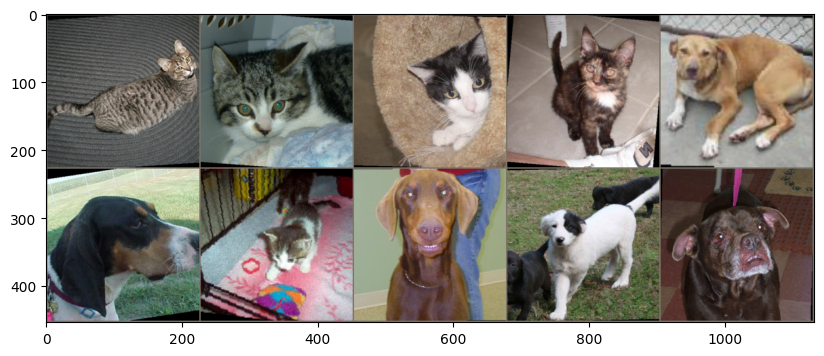

In [14]:
im = make_grid(images, nrow=5)
mean_inv = [-m / s for m, s in zip(mean, std)]
std_inv = [1 / s for s in std]

inv_normalize = transforms.Normalize(mean=mean_inv, std=std_inv)

im_inv = inv_normalize(im)

print("LABELS: ", class_name[labels])
plt.figure(figsize=(12, 4))
plt.imshow(im_inv.permute(1, 2, 0))

In [15]:
# AlexNetmodel = models.alexnet(pretrained=True)
AlexNetmodel = AlexNetEdition()

In [16]:
AlexNetmodel

AlexNetEdition(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Linear(in_features=9216, out_features=1024, bias=True)
    (1): ReLU(inplace=True)
    (

In [17]:
total = 0

for name, param in AlexNetmodel.named_parameters():
    print(name, param.shape)
    total += param.numel()

print(total)

features.0.weight torch.Size([64, 3, 11, 11])
features.0.bias torch.Size([64])
features.3.weight torch.Size([192, 64, 5, 5])
features.3.bias torch.Size([192])
features.6.weight torch.Size([384, 192, 3, 3])
features.6.bias torch.Size([384])
features.8.weight torch.Size([256, 384, 3, 3])
features.8.bias torch.Size([256])
features.10.weight torch.Size([256, 256, 3, 3])
features.10.bias torch.Size([256])
classifier.0.weight torch.Size([1024, 9216])
classifier.0.bias torch.Size([1024])
classifier.3.weight torch.Size([2, 1024])
classifier.3.bias torch.Size([2])
11909954


In [18]:
for param in AlexNetmodel.features.parameters():
    param.requires_grad = False

In [19]:
AlexNetmodel.classifier

Sequential(
  (0): Linear(in_features=9216, out_features=1024, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=1024, out_features=2, bias=True)
)

In [20]:
# AlexNetmodel.model.classifier[5]

In [21]:
# AlexNetmodel.classifier[6]

In [22]:
# # AlexNetmodel.classifier.append(nn.Linear(9216, 1024))
# for i in (5, 5):
#     del AlexNetmodel.classifier[i]
# AlexNetmodel.classifier[1] = nn.Linear(9216, 4096)
# AlexNetmodel.classifier[4] = nn.Linear(4096, 1024)
# del AlexNetmodel.classifier[0]
# AlexNetmodel.classifier


In [23]:
# torch.manual_seed(42)

# AlexNetmodel.classifier = nn.Sequential(
#     nn.Linear(9216, 1024), nn.ReLU(inplace=True), nn.Dropout(0.5), nn.Linear(1024, 2)
# )
# AlexNetmodel

In [24]:
# for param in AlexNetmodel.parameters():
#     print(param.numel())

In [25]:
# criterion = nn.CrossEntropyLoss()
# optimizers = torch.optim.Adam(AlexNetmodel.parameters(), lr=0.001)

In [26]:
# import time

# start_time = time.time()

# # Limits on num of batches
# max_trn_batch = 800  # batch 10 images --> 8000 images
# max_tst_batch = 300  # 3000 max images


# # variables
# epochs = 1
# train_losses = []
# test_losses = []
# train_correct = []
# test_correct = []

# # For loop epochs
# for i in range(epochs):
#     trn_corr = 0
#     tst_corr = 0

#     # train
#     for b, (X_train, y_train) in enumerate(train_loader):
#         # Optinal limit number of batch
#         if b == max_trn_batch:
#             break

#         b += 1

#         y_pred = AlexNetmodel(X_train)  # no flatten
#         loss = criterion(y_pred, y_train)
#         predicted = torch.max(y_pred.data, 1)[1]
#         trn_corr += (predicted == y_train).sum()

#         optimizers.zero_grad()
#         loss.backward()
#         optimizers.step()

#         if b % 200 == 0:
#             acc = trn_corr * 100 / len(X_train) / b
#             print(
#                 f"Epoch: {i + 1:2} Batch: {b:4} [{len(X_train) * b}/{len(train_data)}] loss: {loss.item():2.8f} accuracy: {acc:2.2f}%"
#             )

#     train_losses.append(loss.item())
#     train_correct.append(trn_corr)

#     # validation
#     with torch.no_grad():
#         for b, (X_test, y_test) in enumerate(test_loader):
#             if b == max_tst_batch:
#                 break
#             y_val = AlexNetmodel(X_test)
#             predicted = torch.max(y_val.data, 1)[1]
#             tst_corr += (predicted == y_test).sum()

#     print(f"In Eppch :{i + 1} Accuracy for test data: {tst_corr * 100 / 3000}")
#     loss = criterion(y_val, y_test)
#     test_losses.append(loss.item())
#     test_correct.append(tst_corr)

# during = time.time() - start_time
# mins = during // 60
# secs = during - mins * 60
# print(f"Traning took {mins:2.0f}:{secs:2.0f}")

In [27]:
# test_correct

In [28]:
# print(test_correct[-1].item() * 100 / 3000)

In [29]:
# torch.save(AlexNetmodel, "./models/AlexNetMyEdition.pt")
AlexNetmodel1 = torch.load("./models/AlexNetMyEdition.pt")
AlexNetmodel1


AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Linear(in_features=9216, out_features=1024, bias=True)
    (1): ReLU(inplace=True)
    (2): Dro

In [30]:
torch.save(AlexNetmodel1.state_dict(), "./models/AlexNetMyEdition_weight.pt")
AlexNetmodel2 = AlexNetEdition()

In [31]:
AlexNetmodel2.load_state_dict(torch.load("./models/AlexNetMyEdition_weight.pt"))
AlexNetmodel2

AlexNetEdition(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Linear(in_features=9216, out_features=1024, bias=True)
    (1): ReLU(inplace=True)
    (

In [32]:
CNNmodel = torch.load("./models/CNNCATS_DOGS_fullDataset_10epoches.pt")
CNNmodel

ConvolutionaNetwork_CATS_DOGS(
  (conv1): Conv2d(3, 6, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=46656, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=2, bias=True)
)

real class: DOG---CNN model predicted: DOG---AlexNet model predected: DOG


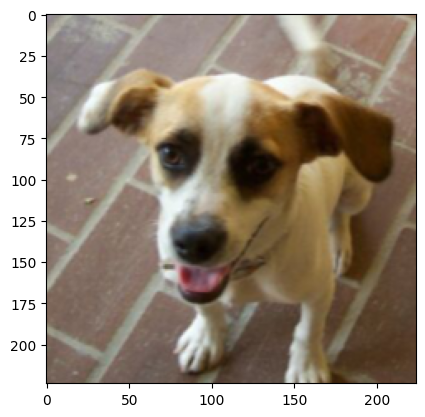

In [33]:
# CNNmodel.eval()
# AlexNetmodel2.eval()

image_index = 5000

with torch.no_grad():
    new_pred_CNN = CNNmodel(test_data[image_index][0].view(1, 3, 224, 224)).argmax()
    new_pred_AlexNet = AlexNetmodel2(
        test_data[image_index][0].view(1, 3, 224, 224)
    ).argmax()

print(
    f"real class: {class_name[test_data[image_index][1]]}---CNN model predicted: {class_name[new_pred_CNN]}---AlexNet model predected: {class_name[new_pred_AlexNet]}"
)


im = inv_normalize(test_data[image_index][0])
plt.imshow(im.permute(1, 2, 0))

LABELS:  ['CAT' 'CAT' 'CAT' 'DOG' 'DOG' 'CAT' 'CAT' 'DOG' 'DOG' 'CAT']


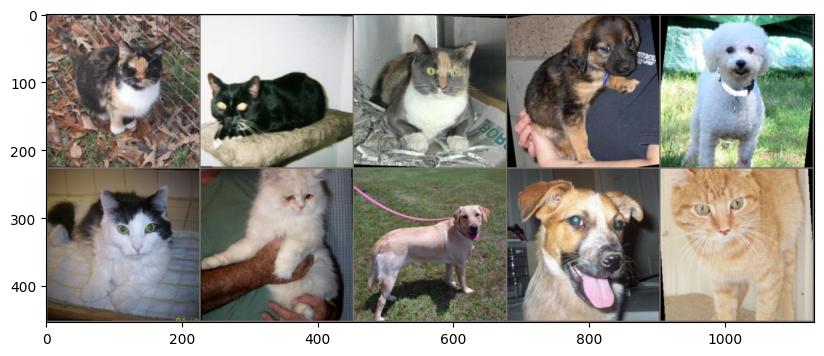

In [34]:
im = make_grid(images, nrow=5)
mean_inv = [-m / s for m, s in zip(mean, std)]
std_inv = [1 / s for s in std]

inv_normalize = transforms.Normalize(mean=mean_inv, std=std_inv)

im_inv = inv_normalize(im)

print("LABELS: ", class_name[labels])
plt.figure(figsize=(12, 4))
plt.imshow(im_inv.permute(1, 2, 0))

In [35]:
inv_normalize

Normalize(mean=[-2.1179039301310043, -2.0357142857142856, -1.8044444444444445], std=[4.366812227074235, 4.464285714285714, 4.444444444444445])

In [36]:
from torchvision import models

model = models.alexnet(weights=models.AlexNet_Weights.DEFAULT)